In [3]:
from scipy import stats
help(stats.linregress)

Help on function linregress in module scipy.stats._stats_py:

linregress(
    x,
    y,
    alternative='two-sided',
    *,
    axis=0,
    nan_policy='propagate',
    keepdims=False
)
    Calculate a linear least-squares regression for two sets of measurements.

    Parameters
    ----------
    x, y : array_like
        Two sets of measurements.  Both arrays should have the same length N.
    alternative : {'two-sided', 'less', 'greater'}, optional
        Defines the alternative hypothesis. Default is 'two-sided'.
        The following options are available:

        * 'two-sided': the slope of the regression line is nonzero
        * 'less': the slope of the regression line is less than zero
        * 'greater':  the slope of the regression line is greater than zero

        .. versionadded:: 1.7.0
    axis : int or None, default: 0
        If an int, the axis of the input along which to compute the statistic.
        The statistic of each axis-slice (e.g. row) of the input will ap

In [9]:
import pandas as pd
import pandas_datareader as web
#
# HERE we get the data of the SP500
start_date = pd.to_datetime('2020-01-01')
end_date = pd.to_datetime('2025-12-12')
spy_etf = web.DataReader('SPY','stooq', start=start_date, end=end_date)
spy_etf.head()


,Open,High,Low,Close,Volume
Date,,,,,
2025-12-12,688.17,688.880,679.1744,681.76,113160347
2025-12-11,685.14,689.250,682.1650,689.17,86173678
2025-12-10,682.56,688.970,681.3100,687.57,85671334
2025-12-09,683.15,685.385,682.5900,683.04,58310055
2025-12-08,686.59,686.640,681.5700,683.63,55231462


In [11]:
#
# HERE we pretend our portfolio is made by AAPL stocks
aapl = web.DataReader('AAPL','stooq', start=start_date, end=end_date)
aapl.head()

,Open,High,Low,Close,Volume
Date,,,,,
2025-12-12,277.900,279.2200,276.82,278.28,39532887
2025-12-11,279.095,279.5900,273.81,278.03,33247986
2025-12-10,277.750,279.7500,276.44,278.78,33038318
2025-12-09,278.160,280.0300,276.92,277.18,32193256
2025-12-08,278.130,279.6693,276.15,277.89,38211832


In [12]:
import matplotlib.pyplot as plt
%matplotlib inline


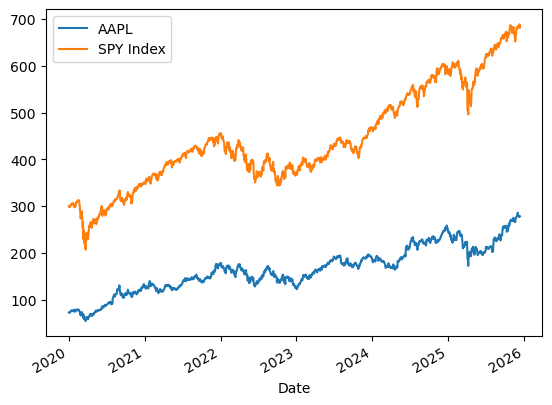

In [13]:
aapl['Close'].plot(label='AAPL')
spy_etf['Close'].plot(label='SPY Index')
plt.legend()

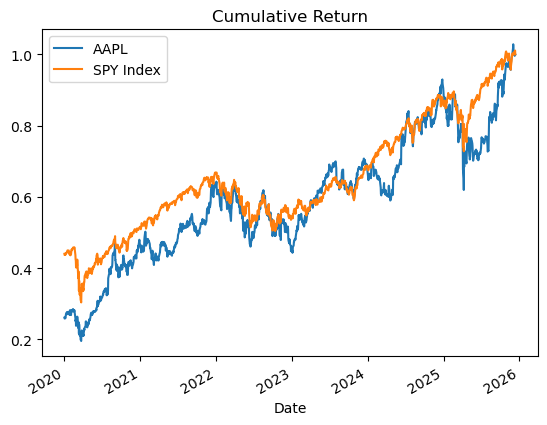

In [ ]:
#
# LET'S COMPARE THEM
#  - CUMULATIVE RETURN
#
aapl['Cumulative'] = aapl['Close'] /  aapl['Close'].iloc[0]
spy_etf['Cumulative'] = spy_etf['Close'] /  spy_etf['Close'].iloc[0]

aapl['Cumulative'].plot(label='AAPL')
spy_etf['Cumulative'].plot(label='SPY Index')
plt.title("Cumulative Return")
plt.legend()
#
# Note that using the old data (i.e. when the course was made AAP was giving a way better cumulative return..)

/var/folders/gn/kqmw_2pn20v4dptbpqx34zfw0000gn/T/ipykernel_26953/41505878.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


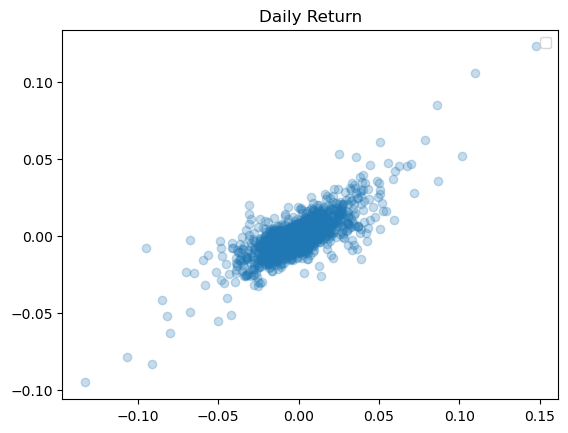

In [ ]:

# LET'S COMPARE THEM
#  - DAILY RETURN
#
aapl['Daily Return'] = aapl['Close'].pct_change(1)
spy_etf['Daily Return'] = spy_etf['Close'].pct_change(1)

plt.scatter(aapl['Daily Return'], spy_etf['Daily Return'], alpha = 0.25)
plt.title("Daily Return")
plt.legend()
#
#
# This data is much more correlated than the data at the time the class was done..

In [ ]:
#
# HERE WE RUN THE REGRESSION
#
beta, alpha, r_value, p_value, std_err = stats.linregress(aapl['Daily Return'].iloc[1:], 
                                                          spy_etf['Daily Return'].iloc[1:]
                                                         )
print("The results are:") 
print(f"----\nBeta             : {beta}")     # Beta should become bigger the more the stock behaves like the market
                                              # of course this goes until it's 1 after that it also means it's not
                                              # following the market
print(f"Alpha            : {alpha}")    # very very small as expected but not zero..
print(f"r (square) value : {r_value}")  # this also gives a meausere of how good is the fit (higher == better fit)
print(f"p value          : {p_value}")
print(f"STD err          : {std_err}") 



The results are:
----
Beta            : 0.51711982667513
Alpha            : -0.00010172489153690304
r (square) value : 0.7861042721903571
p value          : 2.9072768686e-314
STD err          : 0.010522903522150287


In [ ]:
# To prove the points above he tries now to create a set of values starting from the SPY_ETF
# and adding some noise (random normal) that he's adding to the daily return..
# I don't really care about that so not really following through with that